# Extension 2: from wind profile to farm output
### Real turbines, hub-height wind and wakes for the Polish offshore wind pipeline (≈ 30 min)

The main exercise *assumes* a capacity factor of 0.45. Extension 1 replaced it with ERA5 wind at 100 m and a generic power curve with a flat 15 % loss. Here we go one level down, farm by farm:

| Step | Main notebook | Extension 1 | **This extension** |
|---|---|---|---|
| Wind | — | ERA5, 100 m, 2020–2024 | ICON-EU at 80–180 m (2023–2025), DMI HARMONIE-AROME (2025), ERA5 at 10 and 100 m |
| Height | — | 100 m | **hub height of each farm** (141 m Baltic Power, from OpenStreetMap) |
| Turbine | — | generic 15 MW cubic curve | **the turbine model installed at each farm** (OpenStreetMap tags) |
| Layout and wakes | — | flat 15 % loss | **every turbine position from OpenStreetMap**, Jensen wake model per wind direction |
| Result | CF = 0.45 | CF from data | **net CF per project → wind revenue *p*<sub>e</sub> in the SES model** |

**About "real" power curves.** The turbines being installed in Poland — Vestas V236-15.0 MW (Baltic Power), Siemens Gamesa SG 14-222 DD (Baltica 2) and SG 14-236 DD (Bałtyk 2 and 3) — have no published manufacturer power curve. Their **datasheets** give rated power, rotor size, cut-in, rated and cut-out speeds. The only openly published curve of a turbine of this class is the **IEA 15 MW reference turbine** (NREL). So we bracket each turbine's curve between two reconstructions — one anchored on the datasheet's speeds, one on its rotor size — and use their midpoint. Every value below is labelled DATA or ASSUMPTION.

| Time | Part |
|---|---|
| 0–3 min | 0. Setup |
| 3–8 | 1. Which turbines stand where (OpenStreetMap) |
| 8–14 | 2. The wind profile: how much does hub height matter? |
| 14–20 | 3. Power curves and gross capacity factors |
| 20–26 | 4. Wakes from the real layouts |
| 26–30 | 5. Net capacity factor back into the SES model |

## 0. Setup
Same calibrated model and investment timing as the main notebook (scenario S1: contracted wind, ICES harvest rule). Every calculation step is a function in `ses_production.py` and every map or chart a function in `viz.py` (geopandas/folium maps, matplotlib charts, all taking GeoDataFrames, GeoJSON/GeoParquet or DataFrames). This notebook only loads data, sets assumptions and calls them.

All wind data were fetched through the Open-Meteo APIs on 27–30 Oct 2026 and are bundled as histograms (hours per 1 m/s bin, and per 30° direction sector at hub height), because the hourly series for ten sites, three models and six heights would be large. `LIVE = True` refetches one site to show the request.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ses_model import DATA, YEARS, simulate, present_values, fit_surplus_production, build_parameter_set, investment_path, ices_harvest_rule
import ses_production as sp
import viz

LIVE = False
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

ices = pd.read_csv(DATA / "ices_sprat_spr.27.22-32_2025_summary.csv").astype(float)
ices["x"], ices["q"] = ices.SSB / 1e6, ices.Catches / 1e6
ref_row = pd.read_csv(DATA / "ices_sprat_spr.27.22-32_2025_refpoints.csv").iloc[0]
ref = {key: float(ref_row[key]) for key in ["Blim", "Bpa", "MSYBtrigger", "FMSY", "Fpa"]}
econ = pd.read_csv(DATA / "economic_inputs.csv").set_index("parameter")
national = pd.read_csv(DATA / "polish_offshore_wind_pipeline.csv")
growth = fit_surplus_production(ices, fit_from=1974)
P0 = build_parameter_set(ices, econ, growth["alpha"], growth["beta"])
ices_rule = ices_harvest_rule(ref)
Iw_contracted = investment_path(national, years=YEARS, exclude_farms=["Baltic West"])
price = econ.loc["offshore_wind_auction_price_2025", "value"]
base = present_values(simulate(P0, ices_rule, Iw_contracted, start_year=2025), P0, terminal=True)
print("Main notebook S1 (assumed CF 0.45), EUR m:", base.round(0).to_dict())

Main notebook S1 (assumed CF 0.45), EUR m: {'bf': 594.0, 'bw': -118.0, 'bp': 1219.0, 'B': 1695.0}


## 1. Which turbines stand where (5 min)
OpenStreetMap contributors have mapped every foundation position of the four farms under construction, with the turbine model, rotor diameter and, for Baltic Power, the hub height. In an earlier check these positions agreed within 11–21 m with the coordinates in the Maritime Office in Gdynia's safety-zone order for Baltic Power. The snapshot is the raw API response (ODbL 1.0).

Turbines are assigned to farms by an explicit rule — model and `ref` prefix — because only Baltic Power's turbines are members of a mapped wind-farm relation.

In [2]:
assign = pd.read_csv(DATA / "farm_turbine_assignment.csv")
specs = pd.read_csv(DATA / "turbine_specs.csv").set_index("model")
OSM_RULES = {                                          # explicit assignment rule (see text)
    "Baltyk 2": {"ref_prefix": "BK2 "}, "Baltyk 3": {"ref_prefix": "BK3 "},
    "Baltica 2": {"model": "SG 14-222 DD"}, "MFW Baltic Power": {"relation": "relation/21402440"}}
osm_file = DATA / "osm_polish_offshore_wind_2026-10-27.geojson"
turbines = sp.turbines_from_osm(osm_file, OSM_RULES)
summary = sp.layout_summary(turbines, assign, national)
summary

,turbines,model,rotor_m,hub_m_osm,project,unit_mw,hub_m,MW_from_turbines,MW_national
wind_site,,,,,,,,,
Baltica 2,107,SG 14-222 DD,222.0,NaN,Baltica 2,14.0,141,1498.0,1500.0
Baltyk 2,50,SG 14-236 DD,236.0,NaN,Baltyk 2 + Baltyk 3,14.4,150,720.0,720.0
Baltyk 3,50,SG 14-236 DD,236.0,NaN,Baltyk 2 + Baltyk 3,14.4,150,720.0,720.0
MFW Baltic Power,76,V236-15.0 MW,236.0,141,MFW Baltic Power,15.0,141,1140.0,1200.0


In [3]:
osm = viz.to_gdf(osm_file, flatten=["tags"])
viz.explore({
    "farm areas (OSM)": {"data": osm[osm.geom_type == "Polygon"], "color": "#64748b", "style_kwds": {"fillOpacity": .15},
                         "tooltip": ["name", "seamark:name", "operator"]},
    "turbines (OSM)": {"data": turbines, "column": "wind_site", "cmap": "Set1", "marker_kwds": {"radius": 4},
                       "tooltip": ["wind_site", "model", "rotor_d", "hub_m_osm", "ref"]},
    "offshore substations (OSM)": {"data": osm[osm.power == "substation"], "color": "black", "tooltip": ["name", "ref", "voltage"],
                                   "marker_kwds": {"radius": 6}}})

> **Notice.** Baltic Power has 76 × 15 MW = 1140 MW of turbines, but national reporting (and the OSM farm relation) says 1200 MW. Baltica 2's 107 × 14 MW = 1498 MW matches. The difference is the kind of discrepancy the companion notebook on source harmonisation is about.

## 2. The wind profile: how much does hub height matter? (6 min)
Three models, three different strengths:
* **ICON-EU** (DWD, ~7 km): wind speed at 80, 100, 120 and 180 m and direction, 2023–2025 — our main source;
* **DMI HARMONIE-AROME** (2.5 km): same levels, available for 2025 only;
* **ERA5** (ECMWF reanalysis, ~30 km): only 10 m and 100 m, but a long consistent record (used in extension 1).

Values at 141 m and 150 m were interpolated between 120 and 180 m with a logarithmic profile in height, hour by hour, before binning.

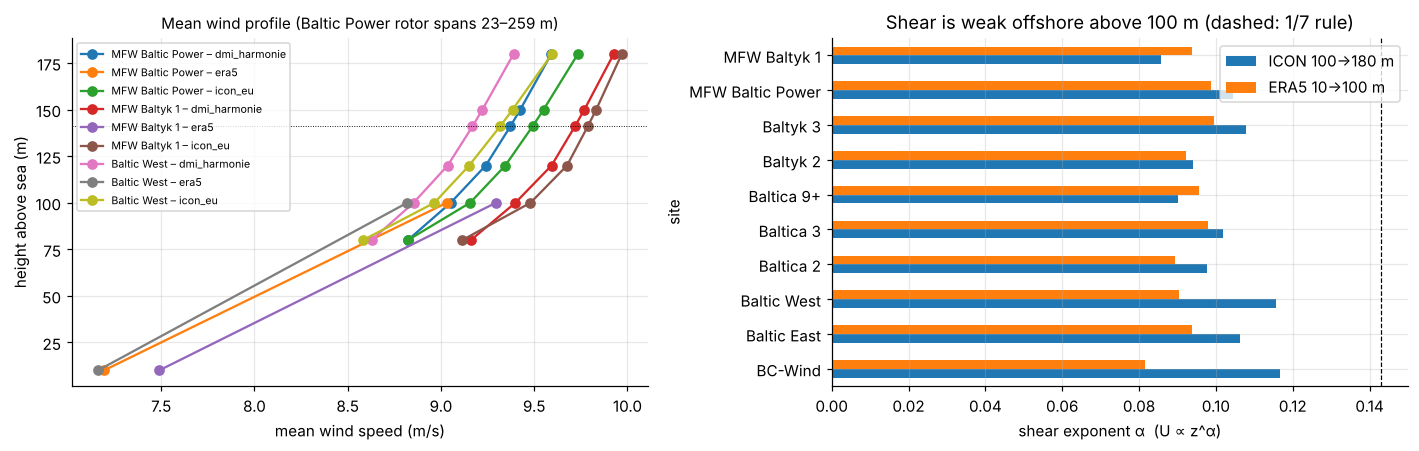

source,dmi_harmonie,era5,icon_eu,ICON − ERA5
site,,,,
BC-Wind,8.89,9.06,9.03,-0.03
Baltic East,9.04,9.05,9.13,0.08
Baltic West,8.85,8.82,8.96,0.15
Baltica 2,9.18,9.17,9.26,0.09
Baltica 3,9.12,9.06,9.19,0.14
Baltica 9+,9.29,9.19,9.38,0.20
Baltyk 2,9.24,9.18,9.32,0.15
Baltyk 3,9.02,8.96,9.13,0.17
MFW Baltic Power,9.05,9.03,9.16,0.12


In [4]:
hist = sp.load_wind_histograms(DATA / "wind_speed_hist_by_height_2023-2025.csv")
profile = sp.mean_profiles(hist)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
lines = profile.loc[["MFW Baltic Power", "MFW Baltyk 1", "Baltic West"]].T
lines.columns = [f"{site} – {source}" for site, source in lines.columns]
viz.profile_plot(lines, ax=ax[0], title="Mean wind profile (Baltic Power rotor spans 23–259 m)")
ax[0].axhline(141, color="k", lw=.6, ls=":")
sp.shear_table(profile).plot.barh(ax=ax[1])
ax[1].axvline(1 / 7, color="k", ls="--", lw=.8)
ax[1].set(xlabel="shear exponent α  (U ∝ z^α)", title="Shear is weak offshore above 100 m (dashed: 1/7 rule)")
plt.tight_layout(); plt.show()
at100 = profile[100].unstack("source")
at100.assign(**{"ICON − ERA5": at100.icon_eu - at100.era5}).round(2)

> **Read the profile.** From 100 m to 180 m the mean speed grows by only 0.5–0.65 m/s: the shear exponent of the mean profile is about 0.09–0.12, below the 1/7 (0.14) rule of thumb, which describes the lowest 100 m over land. At 100 m, ICON-EU is up to 0.2 m/s windier than ERA5. DMI covers 2025 only, so part of its difference is the year, not the model.

## 3. Power curves and gross capacity factors (6 min)

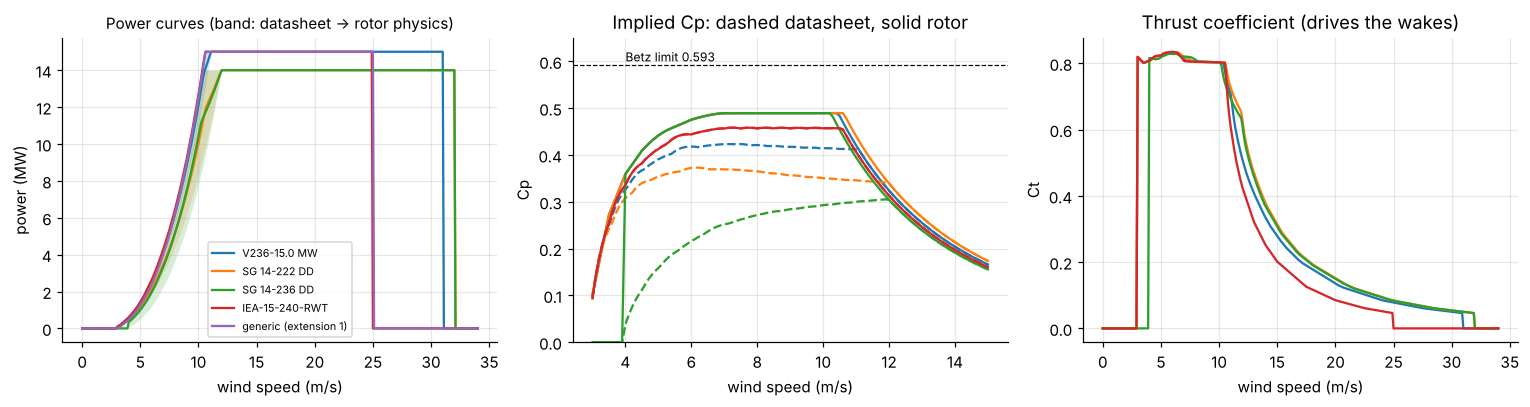

,rated_kw,rotor_d_m,cut_in_ms,rated speed: datasheet,cut_out_ms,rated speed: rotor physics
model,,,,,,
V236-15.0 MW,15000,236,3.0,11.1,31.0,10.46
SG 14-222 DD,14000,222,3.0,12.0,32.0,10.62
SG 14-236 DD,14000,236,4.0,12.0,32.0,10.24
IEA-15-240-RWT,15000,240,3.0,10.6,25.0,NaN


In [5]:
iea = pd.read_csv(DATA / "iea15mw_reference_power_curve.csv")
curves = sp.build_power_curves(specs, iea)
sp.plot_power_curves(curves, specs); plt.show()
sp.rated_speeds(specs, curves).round(2)

Two reconstructions, both labelled ASSUMPTION, bracket each commercial turbine:
* **datasheet-anchored** (dashed Cp): the IEA curve's shape stretched so that cut-in, rated speed and cut-out match the datasheet;
* **rotor-physics** (solid Cp): the IEA rotor's aerodynamic efficiency (Cp ≈ 0.49) applied to the turbine's real swept area, capped at its rated power.

The physics check shows why they differ. Reaching 14 MW only at 12 m/s on a 236 m rotor, as the SG 14-236 DD datasheet states, implies a power coefficient of 0.30 at most — far below what modern rotors achieve. Datasheets often quote a conservative rated speed. With rotor physics the same turbine is at full power by 10.2 m/s. The real curves lie in between; we use the **midpoint** (solid lines) and carry the band.

Now the **gross** capacity factor of a single free-standing turbine for each project:

In [6]:
gross = sp.gross_cf_table(assign, hist, curves, specs)
cf_cols = [c for c in gross.columns if "curve" in c]
gross.style.format({c: "{:.3f}" for c in cf_cols}).background_gradient(subset=cf_cols, cmap="YlGnBu", axis=None)

,project,turbine,hub_m,band at hub (ICON),"generic curve, ERA5 100 m","turbine curve, ERA5 100 m","turbine curve, ICON 100 m","turbine curve, ICON hub","turbine curve, DMI hub (2025)"
wind_site,,,,,,,,,
MFW Baltic Power,MFW Baltic Power,V236-15.0 MW,141,0.551–0.584,0.557,0.554,0.548,0.567,0.572
Baltica 2,Baltica 2,SG 14-222 DD,141,0.515–0.582,0.569,0.536,0.529,0.549,0.558
Baltyk 2,Baltyk 2 + Baltyk 3,SG 14-236 DD,150,0.497–0.607,0.570,0.534,0.531,0.552,0.562
Baltyk 3,Baltyk 2 + Baltyk 3,SG 14-236 DD,150,0.485–0.596,0.551,0.515,0.515,0.540,0.543
BC-Wind,BC-Wind,SG 14-236 DD,150,0.477–0.590,0.553,0.518,0.505,0.534,0.527
Baltica 3,Baltica 3,IEA-15-240-RWT,150,0.578–0.578,0.560,0.567,0.559,0.578,0.589
MFW Baltyk 1,MFW Baltyk 1,IEA-15-240-RWT,150,0.592–0.592,0.581,0.588,0.579,0.592,0.604
Baltica 9+,Baltica 9+,IEA-15-240-RWT,150,0.591–0.591,0.573,0.581,0.576,0.591,0.605
Baltic East,Baltic East,IEA-15-240-RWT,150,0.573–0.573,0.558,0.565,0.553,0.573,0.581


> **Discuss — what moves the answer most?** Read across a row. Changing the dataset at the same height (ERA5 → ICON at 100 m) moves the gross CF by less than 1 percentage point. Going from 100 m to hub height (ICON 100 m → ICON hub) adds about 2 points. The **uncertainty of the power curve** — the band column — spans 3 to 11 points. *For production, knowing the turbine's real curve matters more than knowing the hub height, and hub height more than the choice of reanalysis.*

## 4. Wakes from the real layouts (6 min)
Each turbine slows the wind behind it. The **Jensen (Park) model** treats a wake as a cone that widens linearly downstream (wake decay constant *k* = 0.04, a common offshore value — ASSUMPTION) with a velocity deficit set by the upstream turbine's thrust coefficient; overlapping wakes combine as root-sum-of-squares. We evaluate it for every 30° sector of the hub-height wind rose (five directions per sector) and every 1 m/s speed bin.

First each farm on its own, then the four together. From west to east they are Bałtyk 2, Baltica 2, Bałtyk 3 and Baltic Power, only a few kilometres apart, so the prevailing westerly winds carry each farm's wakes into its eastern neighbour.

In [7]:
roses = sp.load_wind_roses(DATA / "wind_rose_hubheight_icon_eu_2023-2025.csv")
WAKE_K = 0.04                                         # ASSUMPTION: offshore wake decay constant
wakes, turbines, rose_shares = sp.wake_efficiencies(turbines, roses, curves["mid"], k=WAKE_K)
wakes.round(3)

,isolated,in the cluster,"wake loss, isolated (%)","wake loss, cluster (%)"
Baltica 2,0.871,0.855,12.928,14.486
Baltyk 2,0.897,0.880,10.286,11.988
Baltyk 3,0.899,0.893,10.076,10.681
MFW Baltic Power,0.896,0.893,10.385,10.671


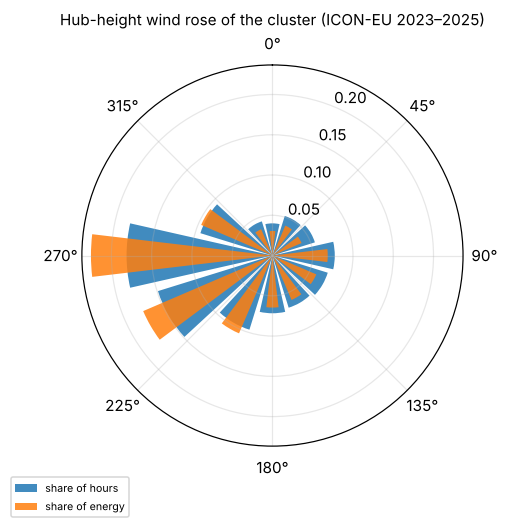

In [8]:
viz.wind_rose(rose_shares, title="Hub-height wind rose of the cluster (ICON-EU 2023–2025)"); plt.show()
viz.explore({"turbine wake efficiency": {"data": turbines, "column": "efficiency", "cmap": "RdYlGn",
                                         "vmin": .78, "vmax": .98, "marker_kwds": {"radius": 5},
                                         "tooltip": ["wind_site", "ref", "model", "efficiency"]}})

> **Read the map.** Westerly and south-westerly winds carry most of the energy, so the turbines on the western edge of each farm lose only 5–6 % and the eastern rows up to 18 %. Baltica 2 loses the most: it is the largest farm and sits directly downwind of Bałtyk 2. Baltic Power, the easternmost, is least affected by its neighbours because Bałtyk 3 is several kilometres upwind. The Jensen model is the simplest engineering wake model; it is known to under-predict losses deep inside very large arrays and ignores blockage, which together are worth a few more percent.

## 5. Net capacity factor back into the SES model (4 min)
$$CF_{net} = CF_{gross}(\text{hub height, turbine curve}) \times \eta_{wake} \times \eta_{availability} \times \eta_{electrical}$$
Farms without a public layout get the capacity-weighted mean wake efficiency of the four modelled farms (an ASSUMPTION). Availability 95 % and electrical efficiency 98 % are typical offshore values (ASSUMPTIONS).

In [9]:
AVAILABILITY, ELECTRICAL = 0.95, 0.98                 # ASSUMPTIONS
projects, eff_default = sp.net_cf_by_project(gross, wakes, assign, national, AVAILABILITY, ELECTRICAL)
projects

,MW,turbine,gross_cf,wake_eff,net_cf,wake,first power
project,,,,,,,
MFW Baltic Power,1200.0,V236-15.0 MW,0.567,0.893,0.472,OSM layout,2026
Baltica 2,1500.0,SG 14-222 DD,0.549,0.855,0.437,OSM layout,2027
Baltyk 2 + Baltyk 3,1440.0,SG 14-236 DD,0.546,0.887,0.451,OSM layout,2028
BC-Wind,390.0,SG 14-236 DD,0.534,0.877,0.436,assumed (mean of modelled farms),2028
Baltica 3,1000.0,IEA-15-240-RWT,0.578,0.877,0.472,assumed (mean of modelled farms),2030
MFW Baltyk 1,1560.0,IEA-15-240-RWT,0.592,0.877,0.484,assumed (mean of modelled farms),2032
Baltica 9+,1300.0,IEA-15-240-RWT,0.591,0.877,0.482,assumed (mean of modelled farms),2032
Baltic East,900.0,IEA-15-240-RWT,0.573,0.877,0.468,assumed (mean of modelled farms),2032
Baltic West,4100.0,IEA-15-240-RWT,0.569,0.877,0.465,assumed (mean of modelled farms),2035


In [10]:
cf_turbines = sp.capacity_weighted(projects)
cf_ext1 = sp.capacity_weighted(gross.groupby("project")["generic curve, ERA5 100 m"].mean().rename("cf")
                               .to_frame().join(projects.MW), column="cf") * (1 - 0.15)
rows = {}
for label, cf in [("Main notebook: assumed", 0.45), ("Extension 1 method: generic curve, ERA5 100 m, −15 %", cf_ext1),
                  ("This extension: turbines, hub height, wakes", cf_turbines)]:
    pe, pv = sp.ses_wind_value(P0, cf, price, ices_rule, Iw_contracted)
    rows[label] = {"CF (contracted, capacity-weighted)": cf, "p_e (EUR m per GW-yr)": pe, "PV wind": pv.bw,
                   "PV fishery": pv.bf, "PV public": pv.bp, "PV total": pv.B}
pd.DataFrame(rows).T.style.format({"CF (contracted, capacity-weighted)": "{:.3f}", "p_e (EUR m per GW-yr)": "{:.0f}",
                                   "PV wind": "{:,.0f}", "PV fishery": "{:,.0f}", "PV public": "{:,.0f}", "PV total": "{:,.0f}"})

,"CF (contracted, capacity-weighted)",p_e (EUR m per GW-yr),PV wind,PV fishery,PV public,PV total
Main notebook: assumed,0.450,453,-118,594,"1,219","1,695"
"Extension 1 method: generic curve, ERA5 100 m, −15 %",0.481,485,"2,088",594,"1,219","3,901"
"This extension: turbines, hub height, wakes",0.464,468,911,594,"1,219","2,724"


How robust is that number? The same calculation with every combination of wind data and curve:

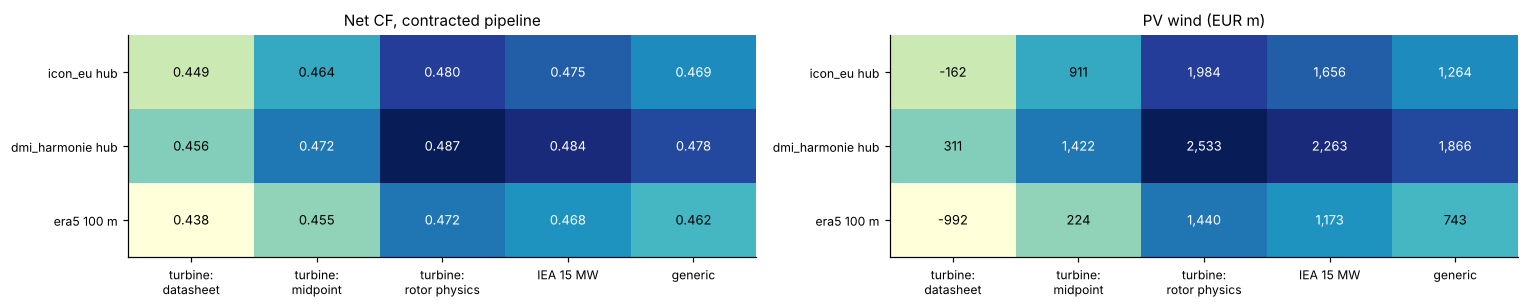

In [11]:
grid = sp.contracted_cf_grid(assign, hist, curves, specs, wakes, national, eff_default, AVAILABILITY, ELECTRICAL)
pv_grid = grid.map(lambda cf: sp.ses_wind_value(P0, cf, price, ices_rule, Iw_contracted)[1].bw)
fig, ax = plt.subplots(1, 2, figsize=(14, 2.9))
viz.heatmap_table(grid, "{:.3f}", "Net CF, contracted pipeline", ax=ax[0])
viz.heatmap_table(pv_grid, "{:,.0f}", "PV wind (EUR m)", ax=ax[1])
plt.tight_layout(); plt.show()

> **Read the results.**
> * With the turbines actually being installed, hub-height wind and the real layouts, the contracted pipeline's net capacity factor is about 0.46 (0.45–0.48 across the curve band) — close to the main notebook's assumed 0.45, but now every part is traceable: gross yields of 0.53–0.59 at hub height, 11–15 % wake losses and 7 % availability and electrical losses.
> * Extension 1's method gave 0.48. Its flat 15 % loss was too optimistic: wakes alone take 11–15 % here.
> * Each percentage point of capacity factor is worth about EUR 700 million of PV wind over the 26 years. The wind dataset moves the pipeline's CF by about ±1 point and the power-curve band by ±1.5 points (up to ±5.5 for a single Siemens Gamesa farm). The manufacturers' certified curves, or SCADA data once the farms operate, would be the most valuable data improvement for the wind side of this twin.

## Your turn
1. **Wake model.** Set `WAKE_K = 0.03` (stable Baltic atmosphere, slower wake recovery) and `0.06`. How much does the contracted CF change? Which farm is most sensitive, and why?
2. **Hub height.** In `data/farm_turbine_assignment.csv` the Bałtyk hub height is an assumption (150 m). Change it to 141 m (re-run from Part 3). Does it matter compared with exercise 1?
3. **Turbine choice.** BC-Wind's turbine is assumed. Re-run with `IEA-15-240-RWT` for it. What does the choice of cut-in speed (4 vs 3 m/s) do to a site with weaker wind?
4. **Neighbours.** Remove Baltica 2 from `turbines` before the cluster run. How much does Baltic Power gain? Who should pay for wake losses imposed on a neighbour — a question for marine spatial planning, not for the model.

## What this extension adds — and what it still assumes
| | Status |
|---|---|
| Turbine positions, models, rotor diameters | **DATA** — OpenStreetMap (ODbL), checked against the Baltic Power safety-zone order |
| Hub height | **DATA** for Baltic Power (OSM), datasheet value for Baltica 2, **ASSUMPTION** (150 m) for the others |
| Turbine datasheet values | **DATA** — rated power, rotor, cut-in, rated and cut-out speed |
| Power and thrust curve *shape* | **ASSUMPTION** — IEA 15 MW reference turbine shape; manufacturer curves are not public |
| Wind profile and rose | **DATA** — model output (ICON-EU, HARMONIE-AROME, ERA5), not measurements; FINO2 or floating LiDAR campaigns would validate it |
| Wake model, *k* = 0.04 | **ASSUMPTION** — Jensen/Park; no blockage, no atmospheric stability |
| Availability, electrical losses | **ASSUMPTIONS** (95 %, 98 %) |
| Farms without a public layout or turbine choice | **ASSUMPTION** — IEA 15 MW at 150 m and the mean modelled wake efficiency |

### Sources
* OpenStreetMap contributors, API 0.6 map call, 27 Oct 2026 (ODbL 1.0): https://www.openstreetmap.org/copyright
* Open-Meteo Historical Forecast API (ICON-EU, DMI HARMONIE-AROME) and Historical Weather API (ERA5): https://open-meteo.com/en/docs/historical-forecast-api — model data © DWD, DMI and Copernicus Climate Change Service
* IEA 15 MW reference turbine curve: NREL `turbine-models`, BSD-3-Clause: https://github.com/NREL/turbine-models ; Gaertner et al. (2020), *Definition of the IEA 15-Megawatt Offshore Reference Wind Turbine*, NREL/TP-5000-75698
* Turbine datasheet values: https://en.wind-turbine-models.com (Vestas V236-15.0, Siemens Gamesa SG 14-222 DD and SG 14-236 DD; no power data published there)
* Jensen, N. O. (1983), *A note on wind generator interaction*, Risø-M-2411; Katić, Højstrup & Jensen (1986), *A simple model for cluster efficiency*, EWEC

In [12]:
if LIVE:                                              # one example request: Baltic Power hub-height profile, 2025
    import requests
    r = requests.get("https://historical-forecast-api.open-meteo.com/v1/forecast", timeout=120, params={
        "latitude": 55.05, "longitude": 17.65, "start_date": "2025-01-01", "end_date": "2025-12-31",
        "hourly": "wind_speed_80m,wind_speed_100m,wind_speed_120m,wind_speed_180m,wind_direction_120m",
        "wind_speed_unit": "ms", "models": "icon_eu"})
    hourly = pd.DataFrame(r.json()["hourly"]); print(hourly.describe().round(2))
else:
    print("LIVE = False: using the bundled histograms (see Part 0).")

LIVE = False: using the bundled histograms (see Part 0).
